# Real source data tour: tomato, nine-MQ, potato environment

**Interpretation warning:** synthetic scores only describe simulator reconstruction. Real source records keep their published target; no unrelated studies are joined.

## Do not merge these sources
The sources measure different things and lack verified shared lot/time IDs. This notebook describes them separately; it does not create a combined training set.

In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'artifacts').exists(): ROOT=ROOT.parent
ART=ROOT/'artifacts'
plt.rcParams.update({'figure.figsize':(9,4.5),'axes.spines.top':False,'axes.spines.right':False})
SRC=ROOT/'data'/'dataset_edition_2'; tomato=SRC/'tomato'/'original'/'zenodo_tomato_12_channel_enose'/'extracted'/'Sensor and Laboratory Data'/'Dataframe_ML_complete.csv'; mqdir=SRC/'tomato'/'original'/'zenodo_exact_nine_mq_tomato_recordings'/'AllSmaples-Report'; potato=SRC/'potato'/'original'/'mendeley_potato_environment'/'extracted'/'Active evaporative cooling by ultrasonic humidific'/'IoT_Data_Consolidee_17noeuds.xlsx'
items=[['Five-crop base','five_crop_120000_simulated_training_bundle/five_crop_120000_ALL_SIMULATED_9MQ.csv','SIMULATED','120,000; 500 lots; 5 crop types'],['Tomato e-nose','data/dataset_edition_2/tomato/original/zenodo_tomato_12_channel_enose/...','REAL SOURCE','52-row ML table; 12 Rs/R0 channels; scenario target'],['Nine-MQ tomato','data/dataset_edition_2/tomato/original/zenodo_exact_nine_mq_tomato_recordings/...','REAL SOURCE','five day-coded short recordings; no lot/inspection key'],['Potato environment','data/dataset_edition_2/potato/original/mendeley_potato_environment/...','REAL SOURCE','66,363 environmental rows; no verified MQ/quality join'],['V2 / V3','data/dataset_edition_2/{tomato,potato,banana}/simulated_v2 or simulated_v3','SIMULATED','generated features and generated labels']]
display(pd.DataFrame(items,columns=['Dataset','Folder relative to project root','Origin','Actual content']))

,Dataset,Folder relative to project root,Origin,Actual content
0,Five-crop base,five_crop_120000_simulated_training_bundle/fiv...,SIMULATED,"120,000; 500 lots; 5 crop types"
1,Tomato e-nose,data/dataset_edition_2/tomato/original/zenodo_...,REAL SOURCE,52-row ML table; 12 Rs/R0 channels; scenario t...
2,Nine-MQ tomato,data/dataset_edition_2/tomato/original/zenodo_...,REAL SOURCE,five day-coded short recordings; no lot/inspec...
3,Potato environment,data/dataset_edition_2/potato/original/mendele...,REAL SOURCE,"66,363 environmental rows; no verified MQ/qual..."
4,V2 / V3,"data/dataset_edition_2/{tomato,potato,banana}/...",SIMULATED,generated features and generated labels


## Tomato e-nose measured table

shape: (52, 20) ; columns: ['Sample ID', 'Storage Scenario', 'Storage Day', 'minitial', 'mcurrent', 'L', 'a', 'b', 'MQ2', 'MQ3_1', 'MQ3_10', 'MQ4', 'MQ5', 'MQ6', 'MQ8', 'MQ9', 'MQ135', 'MQ136', 'MQ137', 'MQ138']


,rows
Storage Scenario,
Tc,18
Trtd,18
Trt,16


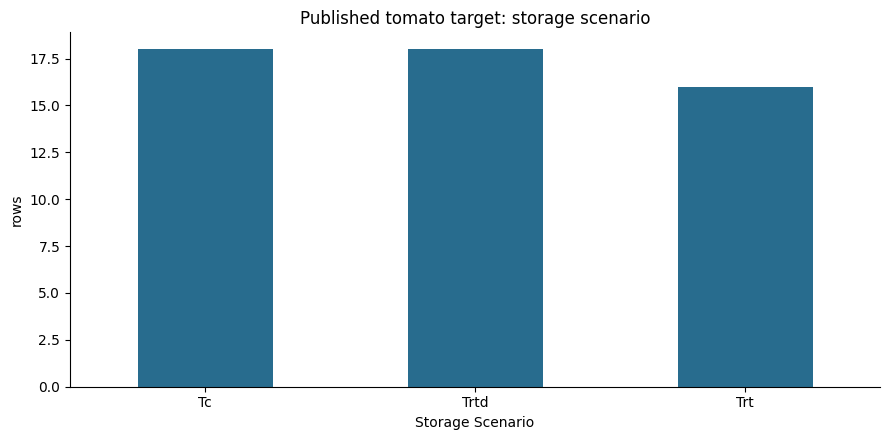

In [2]:
tdf=pd.read_csv(tomato,sep=';'); print('shape:',tdf.shape,'; columns:',list(tdf.columns)); display(tdf['Storage Scenario'].value_counts().to_frame('rows')); tdf['Storage Scenario'].value_counts().plot.bar(color='#286c8e'); plt.title('Published tomato target: storage scenario'); plt.ylabel('rows'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## Tomato nine-MQ recordings (descriptive session medians only)

,MQ2,MQ3,MQ4,MQ5,MQ6,MQ7,MQ8,MQ9,MQ135
Tomato D1,63.0,123.0,76.0,26.0,72.0,51.0,108.0,69.0,695.0
Tomato D2,73.0,244.0,95.0,61.0,109.0,67.0,228.0,105.0,972.0
Tomato D3,83.0,311.0,87.0,67.0,99.0,69.0,237.0,84.0,1239.0
Tomato D4,99.0,433.0,87.0,134.0,115.0,94.0,334.0,80.0,1429.0
tomato D5,98.0,560.0,90.0,233.0,142.0,90.0,389.0,86.0,1735.0


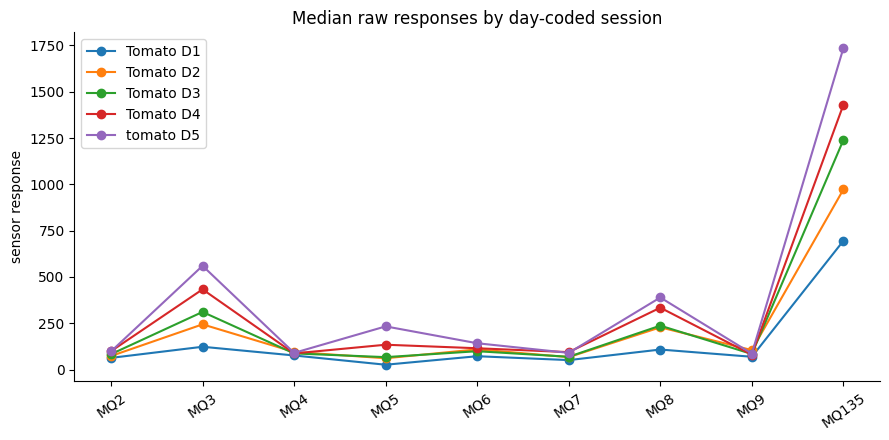

Files are sessions, not verified independent inspected lots; do not split high-frequency points as independent fruits.


In [3]:
channels=['MQ2','MQ3','MQ4','MQ5','MQ6','MQ7','MQ8','MQ9','MQ135']; rows=[]
for f in sorted(mqdir.glob('*Tomato D*.csv')):
 d=pd.read_csv(f); rows.append(d[channels].median().rename(f.stem))
med=pd.DataFrame(rows); display(med.round(1)); med.T.plot(marker='o'); plt.title('Median raw responses by day-coded session'); plt.ylabel('sensor response'); plt.xticks(rotation=35); plt.tight_layout(); plt.show()
print('Files are sessions, not verified independent inspected lots; do not split high-frequency points as independent fruits.')

## Potato measured environment history

shape: (66363, 14) ; invalid timestamps: 0


,count,mean,std,min,25%,50%,75%,max
Temp_Air_C,39127.0,24.86,7.16,-19.97,23.40,26.03,28.24,49.05
Humidite_Relative_pct,39052.0,73.14,20.03,15.62,58.61,75.32,89.07,100.00
Temp_Coeur_Tubercule_C,16286.0,21.54,8.26,6.44,10.50,25.69,27.29,42.13
CO2_ppm,11361.0,546.77,208.19,377.00,437.00,459.00,512.00,1494.00


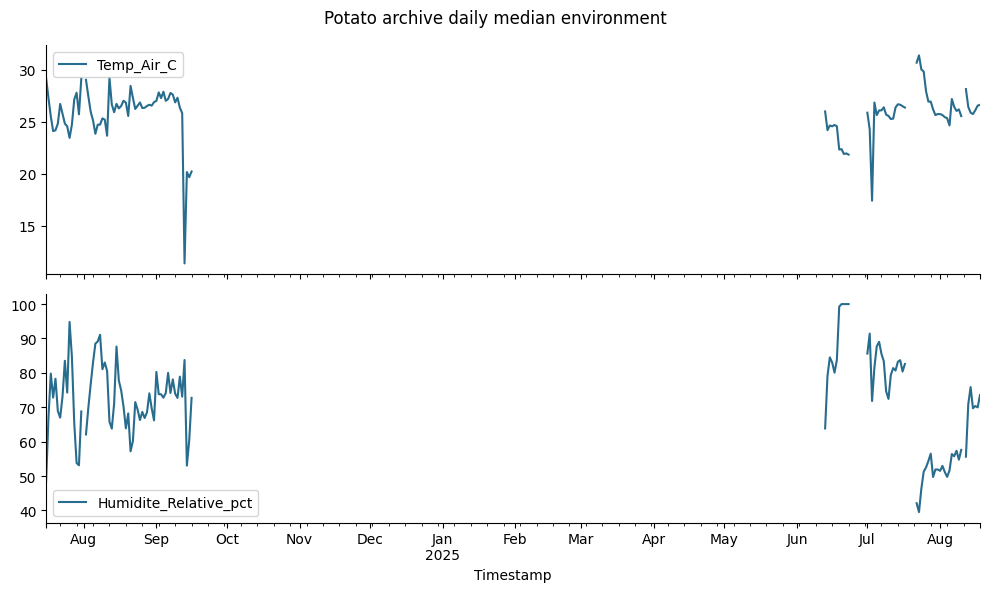

This workbook has no nine-MQ readings and no verified join to individual quality inspections.


In [4]:
pdf=pd.read_excel(potato,sheet_name='Data'); pdf['Timestamp']=pd.to_datetime(pdf['Timestamp'],errors='coerce'); print('shape:',pdf.shape,'; invalid timestamps:',int(pdf.Timestamp.isna().sum())); display(pdf[['Temp_Air_C','Humidite_Relative_pct','Temp_Coeur_Tubercule_C','CO2_ppm']].describe().T.round(2)); daily=pdf.dropna(subset=['Timestamp']).set_index('Timestamp').resample('D')[['Temp_Air_C','Humidite_Relative_pct']].median(); daily.plot(subplots=True,figsize=(10,6),color='#286c8e'); plt.suptitle('Potato archive daily median environment'); plt.tight_layout(); plt.show()
print('This workbook has no nine-MQ readings and no verified join to individual quality inspections.')